# Методы оптимизации в машинном обучении

### О задании

Настоящее практическое задание посвящено методу градиентного спуска и методу Ньютона. Вам предстоит вывести формулы, реализовать методы оптимизации и провести серии экспериментов.

Задание устроено так: сначала идёт короткий блок теории, а сразу за ним — конкретное задание, для выполнения которого этой теории достаточно. Двигайтесь по порядку: прочитали теорию — выполнили задание — проверили себя тестами — перешли к следующему шагу. Так большое задание распадается на небольшие самостоятельные части.

**Файлы, приложенные к заданию**:

* `optimization.py` — прототипы методов оптимизации: линейный поиск, градиентный спуск, метод Ньютона;
* `oracles.py` — прототипы оракулов (квадратичная функция, логистическая регрессия) и разностных производных;
* `plot_trajectory_2d.py` — утилиты для рисования линий уровня функции и траекторий методов;
* `presubmit_tests.py` — предварительные тесты для самопроверки;
* `data/` — наборы данных *w8a*, *gisette*, *real-sim* для финального эксперимента.

Часть функций уже реализована; те, что нужно реализовать вам, помечены комментариями `# TODO`.

**Как проверять себя по ходу работы.** Тесты запускаются через `pytest` (если он не установлен — `pip install pytest`). После каждого задания запускайте предварительные тесты:

```
python -m pytest presubmit_tests.py
```

Что именно сдавать и как оформлять отчёт — описано в последнем разделе «Оформление и проверка задания».

# Часть 1. Методы спуска и линейный поиск

## 1.1 Общая схема метода спуска

Рассматриваем задачу гладкой безусловной оптимизации:
$$\underset{x \in \mathbb{R}^n}{\min} \; f(x).$$

Методы спуска итеративно строят последовательность точек $(x_k)_{k=0}^{\infty}$ из $\mathbb{R}^n$ по правилу
$$x_{k+1} = x_k + \alpha_k d_k.$$

Число $k = 0, 1, \ldots$ называется номером итерации метода. Скаляр $\alpha_k \geq 0$ называется длиной шага, а вектор $d_k \in \mathbb{R}^n$ — направлением поиска. В методах спуска требуется, чтобы направление поиска $d_k$ являлось направлением спуска для функции $f$ в точке $x_k$, т. е. удовлетворяло неравенству
$$\langle \nabla f(x_k), d_k \rangle < 0.$$

В этом случае можно гарантировать, что для всех достаточно маленьких $\alpha_k$ значение функции $f$ в новой точке $x_{k+1}$ уменьшится:
$$f(x_{k+1}) < f(x_k).$$

Общая схема метода спуска приведена ниже.

**Алгоритм 1.** Общая схема метода спуска  
**Вход:** начальная точка $x_0$; максимальное число итераций $K$.  
1: **for** $k \leftarrow 0$ **to** $K$ **do**  
2: &nbsp;&nbsp;&nbsp;&nbsp;*(Вызов оракула)* Вычислить $f(x_k)$, $\nabla f(x_k)$ и пр.  
3: &nbsp;&nbsp;&nbsp;&nbsp;*(Критерий остановки)* Если выполнен критерий остановки, то выход.  
4: &nbsp;&nbsp;&nbsp;&nbsp;*(Вычисление направления)* Вычислить направление спуска $d_k$.  
5: &nbsp;&nbsp;&nbsp;&nbsp;*(Линейный поиск)* Найти подходящую длину шага $\alpha_k$.  
6: &nbsp;&nbsp;&nbsp;&nbsp;*(Обновление)* $x_{k+1} \leftarrow x_k + \alpha_k d_k$.  
7: **end for**  
**Выход:** последняя вычисленная точка $x_k$.

## 1.2 Критерий остановки

Идеальным критерием остановки в методе является проверка условия $f(x_k) - f^* < \tilde{\varepsilon}$, где $f^*$ — минимальное значение функции $f$. Такой критерий целесообразно использовать, если оптимальное значение функции известно заранее. К сожалению, зачастую это не так, и поэтому нужно использовать другой критерий.

Наиболее популярным является критерий, основанный на норме градиента:
$$\|\nabla f(x_k)\|_2^2 < \tilde{\varepsilon}.$$

Квадрат здесь ставят за тем, что для «хороших» функций невязка по функции $f(x_k) - f^*$ имеет тот же порядок, что и $\|\nabla f(x_k)\|_2^2$, а не $\|\nabla f(x_k)\|_2$ (например, это верно для сильно выпуклых функций с липшицевым градиентом); так, если $\|\nabla f(x_k)\|_2 \sim 10^{-5}$, то $f(x_k) - f^* \sim 10^{-10}$.

Наконец, для того, чтобы критерий не зависел от того, в каких единицах измеряется функция $f$ (т. е. не изменялся при переходе от функции $f$ к функции $tf$, где $t > 0$), имеет смысл использовать следующий относительный вариант критерия:
$$\|\nabla f(x_k)\|_2^2 \leq \varepsilon \|\nabla f(x_0)\|_2^2, \tag{1.1}$$
где $\varepsilon \in (0, 1)$ — заданная относительная точность. Критерий остановки (1.1) гарантирует, что метод уменьшит начальную невязку $\|\nabla f(x_0)\|_2$ в $\varepsilon^{-1}$ раз.

**Во всех методах этого задания нужно использовать именно критерий остановки (1.1).**

## 1.3 Линейный поиск

Рассматривается функция
$$\varphi_k(\alpha) := f(x_k + \alpha d_k).$$
Заметим, что
$$\varphi'_k(\alpha) = \langle \nabla f(x_k + \alpha d_k), d_k \rangle.$$
Поскольку $d_k$ является направлением спуска, то $\varphi'_k(0) = \langle \nabla f(x_k), d_k \rangle < 0$.

**Условием Армихо** для $\alpha$ называется выполнение следующего неравенства:
$$\varphi_k(\alpha) \leq \varphi_k(0) + c_1 \alpha \varphi'_k(0),$$
где $c_1 \in (0, 0.5)$ — некоторая константа.

Для поиска точки $\alpha$, удовлетворяющей условию Армихо, обычно используют метод дробления шага (бэктрекинг):

**Алгоритм 2.** Метод дробления шага  
**Вход:** функция $\varphi_k: \mathbb{R}_+ \to \mathbb{R}$; начальная точка $\alpha_k^{(0)}$.  
1: $\alpha \leftarrow \alpha_k^{(0)}$.  
2: **while** $\varphi_k(\alpha) > \varphi_k(0) + c_1 \alpha \varphi'_k(0)$ **do**  
3: &nbsp;&nbsp;&nbsp;&nbsp;$\alpha \leftarrow \alpha / 2$.  
4: **end while**  
**Выход:** $\alpha$.

«Адаптивный» метод подбора шага запоминает величину $\alpha_k$, найденную на текущей итерации, и на следующей итерации начинает процедуру дробления с $\alpha_{k+1}^{(0)} := 2\alpha_k$. Исключение здесь составляют ньютоновские и квазиньютоновские методы — в этих методах процедуру дробления шага всегда нужно начинать с $\alpha_k^{(0)} := 1$.

**Сильные условия Вульфа:**
$$\varphi_k(\alpha) \leq \varphi_k(0) + c_1 \alpha \varphi'_k(0),$$
$$|\varphi'_k(\alpha)| \leq c_2 |\varphi'_k(0)|,$$
где $c_1 \in (0, 0.5)$, $c_2 \in (c_1, 1)$.

Самостоятельно реализовывать схему для сильных условий Вульфа не нужно — используйте библиотечную функцию `line_search` из модуля `scipy.optimize`: она реализует поиск шага по сильным условиям Вульфа. В ней начальная длина шага $\alpha_k^{(0)}$ автоматически выбирается равной 1.

### Задание 1. Линейный поиск — файл `optimization.py`

**Что нужно сделать.** Реализуйте метод `line_search` класса `LineSearchTool` — процедуру подбора длины шага $\alpha_k$ для заданной точки $x_k$ и направления спуска $d_k$. Метод должен поддерживать три стратегии (поле `method`):

* `'Constant'` — постоянный шаг: просто вернуть фиксированное значение `c`;
* `'Armijo'` — метод дробления шага (Алгоритм 2). Стартовое значение шага: `previous_alpha`, если оно передано, иначе `alpha_0`;
* `'Wolfe'` — сильные условия Вульфа: воспользуйтесь библиотечной функцией `scipy.optimize.line_search`, передав ей `c1` и `c2` из параметров объекта. Функция принимает саму функцию и её градиент (`oracle.func` и `oracle.grad`), а также точку `x_k` и направление `d_k`; найденный шаг лежит в поле `.alpha` возвращаемого результата (в старых версиях scipy возвращается кортеж, и шаг — это элемент с индексом 0).

**Важно.** У `scipy.optimize.line_search` есть один недостаток: она иногда не сходится, и в возвращаемом результате `alpha` оказывается равным `None`. Если это произошло, запустите процедуру дробления шага для поиска точки, удовлетворяющей условию Армихо (т. е. сделайте переход к стратегии `'Armijo'`).

В стратегиях Армихо (и в fallback после Вульфа) значения функции и её производной вдоль направления $\varphi_k(\alpha)$ вычисляйте через методы оракула `func_directional` и `grad_directional` — они уже реализованы в базовом классе `BaseSmoothOracle`.

**Как проверить себя:**

```
python -m pytest presubmit_tests.py::test_line_search
```

## 1.4 Градиентный спуск

Градиентный спуск
$$x_{k+1} = x_k - \alpha_k \nabla f(x_k)$$
можно рассматривать как метод спуска, в котором направление поиска $d_k$ равно антиградиенту $-\nabla f(x_k)$, а длина шага $\alpha_k$ выбирается с помощью линейного поиска.

### Задание 2. Градиентный спуск — файл `optimization.py`

**Что нужно сделать.** Реализуйте функцию `gradient_descent` — градиентный спуск по общей схеме из раздела 1.1:

* **направление:** $d_k = -\nabla f(x_k)$;
* **шаг:** $\alpha_k$ подбирается объектом `LineSearchTool` (задание 1). Используйте адаптивный подбор шага из раздела 1.3: на итерации $k \geq 1$ передавайте в линейный поиск `previous_alpha=2 * alpha_{k-1}`;
* **критерий остановки:** критерий (1.1), т. е. $\|\nabla f(x_k)\|_2^2 \leq \text{tolerance} \cdot \|\nabla f(x_0)\|_2^2$. Проверяйте его в начале каждой итерации;
* **превышение числа итераций:** если после `max_iter` итераций критерий так и не выполнен, возвращайте сообщение `'iterations_exceeded'`;
* **ошибки вычислений:** если в процессе вычислений появились значения `None`, `inf` или `nan` (например, из-за переполнения), возвращайте сообщение `'computational_error'`.

Функция возвращает кортеж `(x_star, message, history)`. Форматы возвращаемых значений и структура словаря `history` при `trace=True` подробно описаны в docstring функции — следуйте им. Не забудьте про параметр `display` для отладочного вывода.

**Как проверить себя:**

```
python -m pytest presubmit_tests.py::test_gd_basic presubmit_tests.py::test_gd_1d
```

# Часть 2. Эксперименты с градиентным спуском

В этой части проводятся эксперименты с реализованным градиентным спуском на квадратичных функциях. Оракул квадратичной функции `QuadraticOracle` уже полностью реализован в модуле `oracles`. Он соответствует функции
$$f(x) = \frac{1}{2}\langle Ax, x \rangle - \langle b, x \rangle, \qquad A \in S_{++}^n, \; b \in \mathbb{R}^n.$$

Для рисования линий уровня функции используйте функцию `plot_levels`, а для рисования траекторий метода — функцию `plot_trajectory` из файла `plot_trajectory_2d.py`.

Результаты экспериментов из этой и следующих частей оформляйте в отчёте (требования к отчёту — в последнем разделе).

### Задание 3. Эксперимент: траектория градиентного спуска на квадратичной функции

**Что нужно сделать.** Придумайте две-три квадратичные **двумерные** функции, на которых работа градиентного спуска будет заметно отличаться (например, с разным числом обусловленности). Для каждой из них запустите градиентный спуск из нескольких начальных точек и с разными стратегиями выбора шага (константная, Армихо, Вульф). Нарисуйте графики с линиями уровня функций и траекториями методов (функции `plot_levels` и `plot_trajectory`).

**Вопрос для анализа.** Как отличается поведение метода в зависимости от числа обусловленности функции, выбора начальной точки и стратегии выбора шага? Ответьте на него в отчёте.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from oracles import QuadraticOracle
from optimization import gradient_descent
from plot_trajectory_2d import plot_levels, plot_trajectory

# Матрицы квадратичных функций
A1 = np.array([[1.0, 0.0],[0.0, 1.0]])
A2 = np.array([[5.5, 4.5],[4.5, 5.5]])
A3 = np.array([[50.5, 49.5],[49.5, 50.5]])
b = np.zeros(2)

# Создаем оракулы
oracle1 = QuadraticOracle(A1, b)
oracle2 = QuadraticOracle(A2, b)
oracle3 = QuadraticOracle(A3, b)

# Проверяем числа обусловленности
for A in [A1, A2, A3]:
    eigenvalues = np.linalg.eigvalsh(A)
    kappa = eigenvalues[-1] / eigenvalues[0]
    print(f"Собственные значения: {eigenvalues}")
    print(f"Число обусловленности: {kappa:.1f}")
    print()

Собственные значения: [1. 1.]
Число обусловленности: 1.0

Собственные значения: [ 1. 10.]
Число обусловленности: 10.0

Собственные значения: [  1. 100.]
Число обусловленности: 100.0



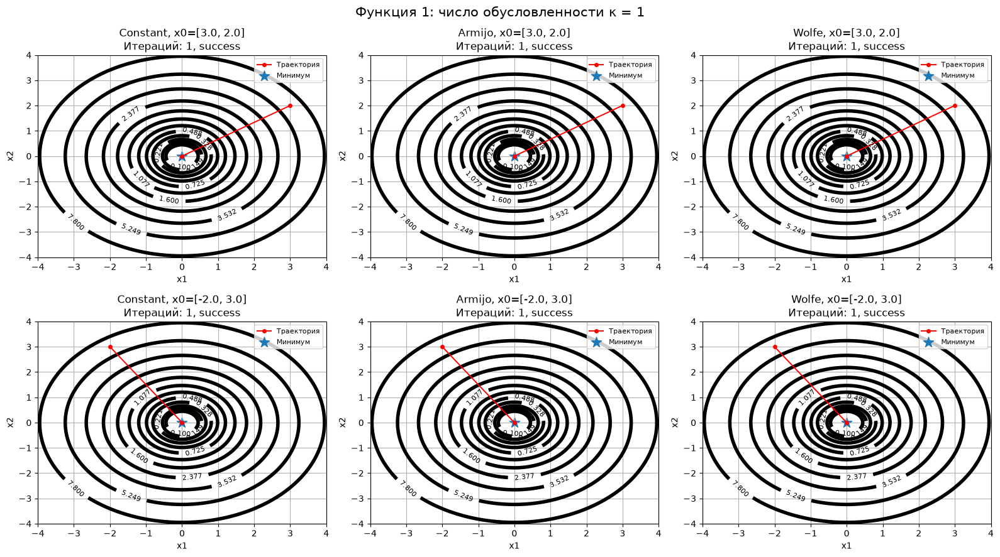

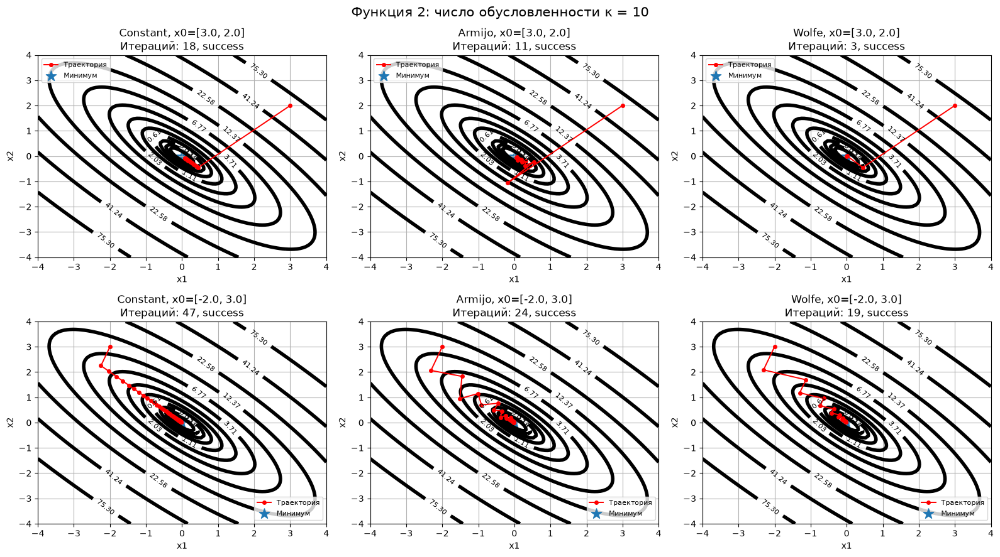

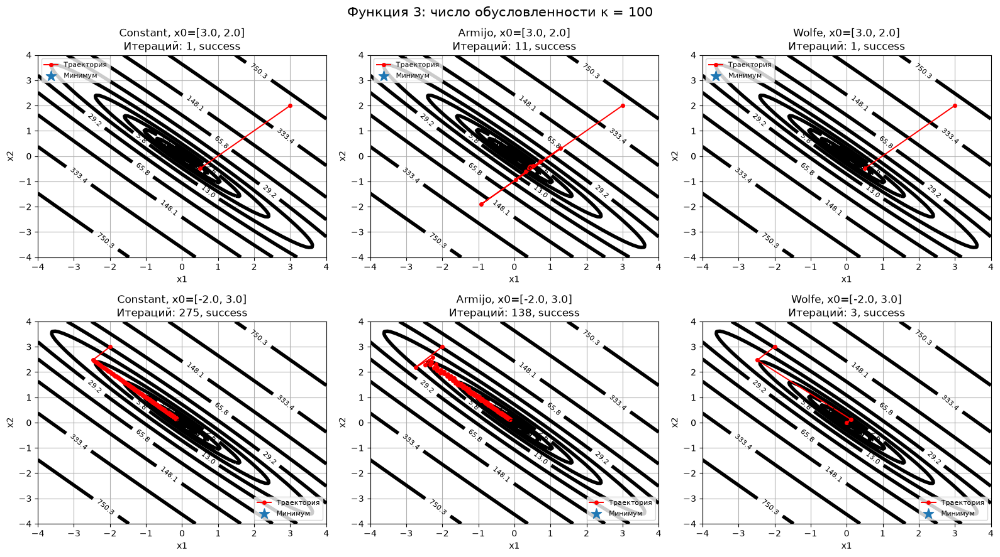

In [2]:
# Наши функции
functions = [('Функция 1', A1),('Функция 2', A2),('Функция 3', A3)]

# Начальные точки
start_points = [np.array([3.0, 2.0]),np.array([-2.0, 3.0])]
methods = ['Constant', 'Armijo', 'Wolfe']
results = []

for func_name, A in functions:
    oracle = QuadraticOracle(A, b)
    eigenvalues = np.linalg.eigvalsh(A)
    kappa = eigenvalues[-1] / eigenvalues[0]
    # Для постоянного шага берем 1 / lambda_max
    constant_step = 1.0 / eigenvalues[-1]
    method_options = {'Constant': {'method': 'Constant', 'c': constant_step},'Armijo': {'method': 'Armijo'},'Wolfe': {'method': 'Wolfe'}}

    # Уровни для линий уровня
    max_value = max(oracle.func(x0) for x0 in start_points)
    levels = np.geomspace(0.1, max_value * 1.2, 12)

    plt.figure(figsize=(16, 9))

    for i, x0 in enumerate(start_points):
        for j, method in enumerate(methods):
            x_star, message, history = gradient_descent(oracle,x0,tolerance=1e-5,max_iter=1000,line_search_options=method_options[method],trace=True)
            iterations = len(history['func']) - 1
            results.append({'Функция': func_name,'kappa': kappa,'Начальная точка': str(x0),'Метод': method,'Итерации': iterations,'Результат': message})
            plt.subplot(2, 3, i * 3 + j + 1)
            plot_levels(oracle.func,xrange=[-4, 4],yrange=[-4, 4],levels=levels)
            #plot_trajectory(oracle.func,history['x'],label='Траектория')
            trajectory = np.array(history['x'])
            plt.plot(trajectory[:, 0],trajectory[:, 1],'-o',linewidth=1.4,markersize=4,color='red',label='Траектория')
            plt.scatter(0, 0,marker='*',s=150,label='Минимум')
            plt.xlabel('x1')
            plt.ylabel('x2')
            plt.title(f'{method}, x0={x0.tolist()}\n'f'Итераций: {iterations}, {message}')
            plt.legend(fontsize=8)

    plt.suptitle(f'{func_name}: число обусловленности κ = {kappa:.0f}',fontsize=15)
    plt.tight_layout()
    plt.show()

Вывод по заданию 3

В данном эксперименте исследовали поведение градиентного спуска на трёх квадратичных функциях с числами обусловленности 1, 10 и 100.
При k=1 линии уровня имеют форму окружностей, а все три стратегии выбора шага позволили достичь критерия остановки за одну итерацию.
При увеличении числа обусловленности линии уровня становятся более вытянутыми эллипсами, что затрудняет движение к минимуму и может увеличивать количество итераций. Эксперименты также показали, что скорость сходимости существенно зависит от начальной точки. Например, при k=100 метод с постоянным шагом выполнил критерий остановки за одну итерацию из точки (3,2), но потребовал 275 итераций из точки (-2,3).
Сравнение способов выбора шага показало, что в рассмотренных экспериментах метод Вульфа часто требовал меньше итераций, чем постоянный шаг и метод Армихо. Однако количество итераций не учитывает вычислительную стоимость самого линейного поиска.
Таким образом, на эффективность градиентного спуска влияют число обусловленности функции, выбор начальной точки и стратегия подбора длины шага. При этом большое число обусловленности не обязательно означает большое количество итераций для любой конкретной начальной точки.
льной точки.

### Задание 4. Эксперимент: число итераций градиентного спуска в зависимости от числа обусловленности и размерности

**Что нужно сделать.** Исследуйте, как зависит число итераций $T(n, \kappa)$, необходимое градиентному спуску для сходимости (успешному выходу по критерию остановки), от двух параметров: 1) числа обусловленности $\kappa \geq 1$ оптимизируемой функции и 2) размерности пространства $n$.

Для заданных $n$ и $\kappa$ сгенерируйте случайную квадратичную задачу размера $n$ с числом обусловленности $\kappa$ и запустите на ней градиентный спуск с некоторой фиксированной требуемой точностью. Замерьте число итераций, которое потребовалось методу до сходимости.

Схема эксперимента. Зафиксируйте значение размерности $n$. Переберите различные числа обусловленности $\kappa$ по сетке и постройте график зависимости $T(n, \kappa)$ от $\kappa$. Поскольку каждый раз квадратичная задача генерируется случайным образом, повторите эксперимент несколько раз — в итоге для фиксированного $n$ получится целое семейство кривых, нарисуйте их все одним цветом (например, красным). Теперь увеличьте $n$ и повторите эксперимент: новое семейство кривых нарисуйте другим цветом (например, синим). Повторите процедуру для нескольких значений $n$. Какие выводы можно сделать из полученной картинки?

**Рекомендация.** Проще всего сгенерировать случайную квадратичную задачу размера $n$ с числом обусловленности $\kappa$ следующим образом. В качестве матрицы $A \in S_{++}^n$ удобно взять просто диагональную матрицу $A = \mathrm{Diag}(a)$, у которой диагональные элементы сгенерированы случайно в пределах $[1, \kappa]$, причём $\min(a) = 1$, $\max(a) = \kappa$. В качестве вектора $b \in \mathbb{R}^n$ можно взять вектор со случайными элементами. Диагональные матрицы удобно рассматривать, поскольку с ними можно эффективно работать даже при больших значениях $n$; рекомендуется хранить матрицу $A$ в формате разреженной диагональной матрицы (см. `scipy.sparse.diags`).

Обратите внимание, что значения размерности $n$ имеет смысл перебирать по логарифмической сетке (например, $n = 10$, $n = 100$, $n = 1000$ и т. д.). Если вы используете случайность — зафиксируйте `seed`, чтобы результат был воспроизводимым.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse
import pandas as pd
from oracles import QuadraticOracle
from optimization import gradient_descent

# Размерности пространства
n_values = [10, 100, 1000]

# Числа обусловленности
kappa_values = [1, 2, 5, 10, 20, 50, 100]

# Количество повторений
repeats = 3

# Параметры градиентного спуска
tolerance = 1e-5
max_iter = 10000


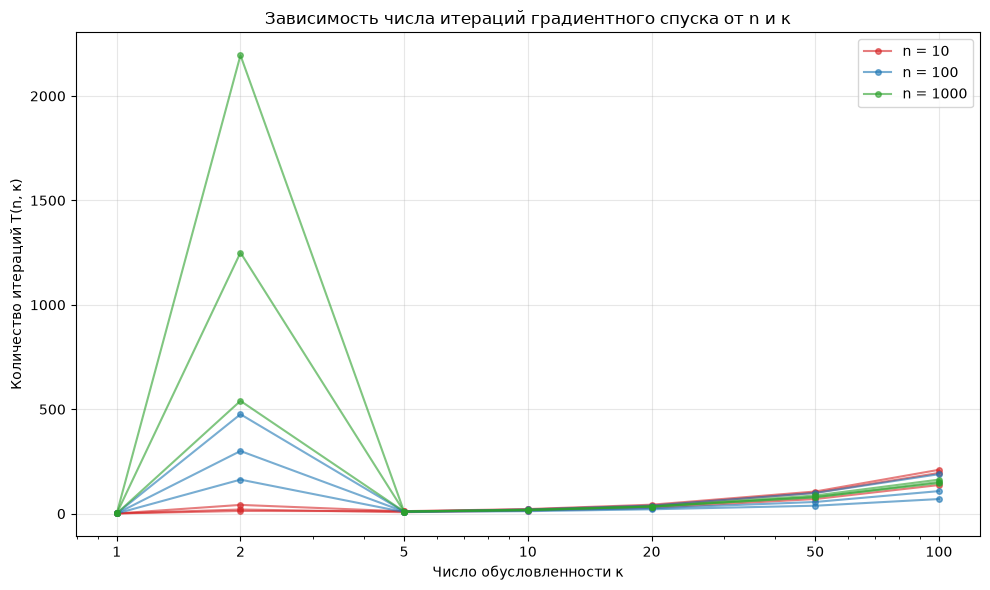

In [4]:
# Фиксируем генератор случайных чисел
rng = np.random.default_rng(21)

# Список для сохранения результатов
results = []

# Цвет для каждой размерности
colors = ['tab:red', 'tab:blue', 'tab:green']
plt.figure(figsize=(10, 6))

# Перебираем размерности
for i, n in enumerate(n_values):

    # Повторяем эксперимент несколько раз
    for repeat in range(repeats):

        # Случайные числа от 0 до 1
        u = rng.uniform(0, 1, size=n)

        # Фиксируем минимум и максимум
        u[0] = 0.0
        u[1] = 1.0
        rng.shuffle(u)

        # Создаём вектор b и начальную точку
        b = rng.normal(size=n)
        x_0 = np.zeros(n)

        # Число итераций для каждого kappa
        t_values = []

        # Перебираем числа обусловленности
        for kappa in kappa_values:

            # Создаём диагональ матрицы A
            a = 1 + (kappa - 1) * u

            # Разреженная диагональная матрица
            A = scipy.sparse.diags(a, format='dia')

            # Оракул квадратичной функции
            oracle = QuadraticOracle(A, b)

            # Запускаем градиентный спуск
            x_star, message, history = gradient_descent(
                oracle,
                x_0,
                tolerance=tolerance,
                max_iter=max_iter,
                line_search_options={'method': 'Armijo'},
                trace=True
            )

            # Подсчитываем количество итераций
            iterations = len(history['func']) - 1

            # Учитываем только успешную сходимость
            if message == 'success':
                t_values.append(iterations)
            else:
                t_values.append(np.nan)

            # Сохраняем результат
            results.append({
                'n': n,
                'kappa': kappa,
                'repeat': repeat + 1,
                'iterations': iterations if message == 'success' else np.nan,
                'status': message
            })

        # Рисуем кривую одного повторения
        plt.plot(
            kappa_values,
            t_values,
            'o-',
            color=colors[i],
            linewidth=1.5,
            markersize=4,
            alpha=0.6,
            label=f'n = {n}' if repeat == 0 else None
        )

plt.xscale('log')
plt.xticks(kappa_values, [str(k) for k in kappa_values])
plt.xlabel('Число обусловленности κ')
plt.ylabel('Количество итераций T(n, κ)')
plt.title('Зависимость числа итераций градиентного спуска от n и κ')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
# Создаем таблицу всех запусков
df = pd.DataFrame(results)

# Среднее количество итераций для каждой пары (n, kappa)
mean_iterations = df.pivot_table(
    index='kappa',
    columns='n',
    values='iterations',
    aggfunc='mean'
)

print("Среднее число итераций:")
display(mean_iterations)


Среднее число итераций:


n,10,100,1000
kappa,,,
1,1.000000,1.000000,1.000000
2,25.000000,313.000000,1328.333333
5,10.000000,9.333333,10.000000
10,19.000000,16.000000,17.666667
20,36.333333,28.666667,34.000000
50,92.000000,64.333333,81.666667
100,180.666667,122.333333,153.666667


Вывод по заданию 4

В ходе эксперимента исследовалась зависимость числа итераций градиентного спуска от числа обусловленности k и размерности пространства n. Для этого использовались случайные квадратичные функции с размерностями n=10, 100, 1000 и различные значения числа обусловленности.
При k = 1 градиентный спуск сходился за одну итерацию независимо от размерности. В целом при увеличении числа обусловленности от 5 до 100 наблюдается рост количества итераций. Зависимость не является строго монотонной, при k = 2 наблюдается резкое увеличение числа итераций, особенно для n = 1000, где среднее значение составило около 1328. Такой результат может быть связан с особенностями выбора шага методом Армихо и конкретными случайно сгенерированными задачами.При этом увеличение размерности не всегда приводит к увеличению количества итераций. Например, при k = 100 для n=10 потребовалось в среднем около 181 итерации, а для n = 100 около 122.
Таким образом, результаты показывают, что скорость сходимости градиентного спуска существенно зависит от числа обусловленности, но на неё также влияют выбор шага и особенности конкретной функции. Сама размерность пространства не определяет количество итераций однозначно.
днозначно.

# Часть 3. Метод Ньютона

Метод Ньютона:
$$x_{k+1} = x_k - \alpha_k [\nabla^2 f(x_k)]^{-1} \nabla f(x_k).$$

Для метода Ньютона очень важно использовать единичный шаг $\alpha_k = 1$, чтобы обеспечить локальную квадратичную сходимость. Поэтому в алгоритмах линейного поиска нужно всегда первым делом пробовать единичный шаг. Теория гарантирует, что в зоне квадратичной сходимости метода Ньютона единичный шаг будет удовлетворять условиям Армихо/Вульфа и поэтому будет приниматься автоматически. Если единичный шаг не удовлетворяет условиям Армихо/Вульфа, то алгоритмы линейного поиска его уменьшат и тем самым обеспечат глобальную сходимость метода Ньютона.

Вычисление ньютоновского направления $d_k = -[\nabla^2 f(x_k)]^{-1} \nabla f(x_k)$ эквивалентно решению линейной системы уравнений
$$\nabla^2 f(x_k)\, d_k = -\nabla f(x_k).$$
Если гессиан — положительно определённая матрица ($\nabla^2 f(x_k) \succ 0$), то предпочтительным методом решения такой системы является разложение Холецкого: как и метод Гаусса, оно работает за $O(n^3)$, но является вычислительно более эффективным. Если матрица системы не является положительно определённой, то разложение Холецкого сможет обнаружить это и сообщить (бросить исключение).

### Задание 5. Метод Ньютона — файл `optimization.py`

**Что нужно сделать.** Реализуйте функцию `newton` по аналогии с `gradient_descent` из задания 2. Отличия:

* **направление:** $d_k = -[\nabla^2 f(x_k)]^{-1} \nabla f(x_k)$. Для его вычисления решайте линейную систему $\nabla^2 f(x_k)\, d_k = -\nabla f(x_k)$;
* **линейный поиск:** на каждой итерации начинайте подбор шага с единичного, $\alpha_k^{(0)} = 1$ (см. теорию выше);
* **новое сообщение об ошибке:** если гессиан в текущей точке не оказался положительно определённым и систему не удалось решить, возвращайте `'newton_direction_error'`.

Остальное — критерий остановки (1.1), заполнение `history` при `trace=True`, сообщения `'iterations_exceeded'` и `'computational_error'` — так же, как в градиентном спуске; точные форматы описаны в docstring функции.

**Важно.** Для поиска направления не нужно обращать гессиан в явном виде (функция `np.linalg.inv`) и не нужно использовать самый общий метод решения системы линейных уравнений (`numpy.linalg.solve`). Учтите тот факт, что в рассматриваемой задаче гессиан является симметричной положительно определённой матрицей, и воспользуйтесь разложением Холецкого (функции `scipy.linalg.cho_factor` и `scipy.linalg.cho_solve`).

**Как проверить себя:**

```
python -m pytest presubmit_tests.py::test_newton_basic presubmit_tests.py::test_newton_1d presubmit_tests.py::test_newton_fail
```

# Часть 4. Логистическая регрессия

## 4.1 Двухклассовая логистическая регрессия

Логистическая регрессия является стандартной моделью в задачах классификации. Для простоты рассмотрим лишь случай бинарной классификации. Неформально задача формулируется следующим образом. Имеется обучающая выборка $(a_i, b_i)_{i=1}^m$, состоящая из $m$ векторов $a_i \in \mathbb{R}^n$ (называемых признаками) и соответствующих им чисел $b_i \in \{-1, 1\}$ (называемых классами). Нужно построить алгоритм $b(\cdot)$, который для произвольного нового вектора признаков $a$ автоматически определит его класс $b(a) \in \{-1, 1\}$.

В модели логистической регрессии определение класса выполняется по знаку линейной комбинации компонент вектора $a$ с некоторыми фиксированными коэффициентами $x \in \mathbb{R}^n$:
$$b(a) := \mathrm{sign}(\langle a, x \rangle).$$

Коэффициенты $x$ являются параметрами модели и настраиваются с помощью решения следующей оптимизационной задачи:
$$\underset{x \in \mathbb{R}^n}{\min} \left( \frac{1}{m} \sum_{i=1}^m \ln(1 + \exp(-b_i \langle a_i, x \rangle)) + \frac{\lambda}{2} \|x\|_2^2 \right),$$
где $\lambda > 0$ — коэффициент регуляризации (параметр модели).

### Задание 6. Формулы для функции, градиента и гессиана — в отчёт

**Что нужно сделать.** Получите формулы для градиента и гессиана функции логистической регрессии из раздела 4.1. Выпишите их в отчёт **в матрично-векторной форме**, с использованием поэлементных функций, но без каких-либо суммирований. Также выпишите в отчёт выражение для самой функции логистической регрессии в матрично-векторной форме (без явных суммирований).

**Замечание.** В матрично-векторной форме допускается использование операций матричного сложения/произведения, умножения на скаляр, транспонирования, стандартного скалярного произведения, поэлементного произведения, а также применения ко всем элементам вектора некоторой скалярной функции. Кроме этого, допускается использование стандартных матриц/векторов (заданного размера): единичная матрица $I_n$, нулевая матрица $0_{m \times n}$, нулевой вектор $0_n$, вектор из всех единиц $1_n := (1, \ldots, 1)$.

Свои выкладки можно сверить со справкой, приведённой ниже.


### Задание 6. Вывод формул логистической регрессии

**Страница 1.**

![Страница 1](Страница_1.jpeg)

**Страница 2.**

![Страница 2](Страница_2.jpeg)

**Страница 3.**

![Страница 3](Страница_3.jpeg)

**Страница 4.**

![Страница 4](Страница_4.jpeg)

**Страница 5.**

![Страница 5](Страница_5.jpeg)

## Справка: функция, градиент и гессиан логистической регрессии

Ниже приведены формулы из задания 6 — пользуйтесь ими как шпаргалкой при реализации оракула (задание 7).

Обозначим $z := b \odot (Ax) \in \mathbb{R}^m$, где $\odot$ — поэлементное умножение, а все скалярные функции ($\ln$, $\exp$, $\sigma$) применяются к векторам поэлементно. Тогда

$$f(x) = \frac{1}{m}\, \mathbf{1}_m^T \ln\!\big(1 + e^{-z}\big) + \frac{\lambda}{2} \|x\|_2^2,$$

$$\nabla f(x) = -\frac{1}{m}\, A^T \big( b \odot \sigma(-z) \big) + \lambda x, \qquad \sigma(t) := \frac{1}{1 + e^{-t}},$$

$$\nabla^2 f(x) = \frac{1}{m}\, A^T\, \operatorname{Diag}(s)\, A + \lambda I_n, \qquad s := \sigma(-z) \odot \big(1 - \sigma(-z)\big).$$

**Как считать это в numpy/scipy (без переполнений и с поддержкой разреженных матриц):**

* $\ln(1 + e^{-z})$ — функция `np.logaddexp(0, -z)`: она эквивалентна «в лоб», но не переполняется при больших $|z|$;
* сигмоида $\sigma(z)$ — функция `scipy.special.expit(z)`;
* произведения $Ax$ и $A^T y$ — методы `A.dot(x)` и `A.T.dot(y)`: они одинаково работают и для плотных матриц `np.array`, и для разреженных `scipy.sparse.csr_matrix`;
* в гессиане произведение $A^T\, \operatorname{Diag}(s)\, A$ не нужно считать через явную диагональную матрицу — достаточно поэлементно домножить строки $A$ на вектор $s$: для плотной матрицы это `A * s[:, None]`, для разреженной — метод `A.multiply(s[:, None])` (тип матрицы проверяется функцией `scipy.sparse.issparse`);
* слагаемое $\lambda I_n$ — это `regcoef * np.eye(n)`.

## 4.2 Разностная проверка градиента и гессиана

Проверить правильность реализации подсчёта градиента можно с помощью конечных разностей:
$$[\nabla f(x)]_i \approx \frac{f(x + \varepsilon_1 e_i) - f(x)}{\varepsilon_1},$$
где $e_i := (0, \ldots, 0, 1, 0, \ldots, 0)$ — $i$-й базисный орт, а $\varepsilon_1$ — достаточно маленькое положительное число: $\varepsilon_1 \sim \sqrt{\varepsilon_{mach}}$, где $\varepsilon_{mach}$ — машинная точность ($\approx 10^{-16}$ для типа `double`).

Вторые производные:
$$[\nabla^2 f(x)]_{ij} \approx \frac{f(x + \varepsilon_2 e_i + \varepsilon_2 e_j) - f(x + \varepsilon_2 e_i) - f(x + \varepsilon_2 e_j) + f(x)}{\varepsilon_2^2},$$
здесь $\varepsilon_2 \sim \sqrt[3]{\varepsilon_{mach}}$.

### Задание 7. Оракул логистической регрессии и разностные производные — файл `oracles.py`

**Что нужно сделать.**

1. Реализуйте оракул логистической регрессии: методы `func`, `grad` и `hess` класса `LogRegL2Oracle` (используйте формулы из задания 6). Оракул создаётся напрямую по данным: `LogRegL2Oracle(A, b, regcoef)`.
2. Реализуйте функции `grad_finite_diff` и `hess_finite_diff` — разностные аппроксимации градиента и гессиана (формулы из раздела 4.2).
3. Проверьте правильность реализации оракула: сгенерируйте небольшую модельную выборку (матрицу $A$ и вектор $b$) и сравните значения, выдаваемые методами `grad` и `hess`, с соответствующими разностными аппроксимациями в нескольких пробных точках $x$. Эту проверку удобно оформить отдельной ячейкой и привести в отчёте.

**Замечания.**

* Реализация оракула должна быть полностью векторизованной, т. е. код не должен содержать никаких циклов по элементам выборки.
* Ваш код должен поддерживать как плотные матрицы $A$ типа `np.array`, так и разреженные типа `scipy.sparse.csr_matrix` (конкретные приёмы — в справке выше).
* Нигде в промежуточных вычислениях не стоит вычислять значение $\exp(-b_i \langle a_i, x \rangle)$, иначе может произойти переполнение. Вместо этого следует напрямую вычислять необходимые величины с помощью специализированных функций: `np.logaddexp` для $\ln(1 + \exp(\cdot))$ и `scipy.special.expit` для $1 / (1 + \exp(\cdot))$.

**Как проверить себя:**

```
python -m pytest presubmit_tests.py::test_log_reg_usual presubmit_tests.py::test_grad_finite_diff_1 presubmit_tests.py::test_grad_finite_diff_2 presubmit_tests.py::test_hess_finite_diff_1 presubmit_tests.py::test_hess_finite_diff_2
```

### Сравнение в пробных точках

In [6]:
from oracles import (LogRegL2Oracle, grad_finite_diff, hess_finite_diff)

# Фиксируем генератор случайных чисел
rng = np.random.default_rng(22)

# Создаём небольшую выборку:
# 6 объектов и 3 признака
A = rng.normal(size=(6, 3))
b = np.array([1, -1, 1, -1, 1, -1])
regcoef = 0.2

# Создаём логистический оракул
oracle = LogRegL2Oracle(A, b, regcoef)

# Три пробные точки
points = [np.zeros(3), np.array([0.3, -0.2, 0.1]), np.array([-0.5, 0.4, 0.2])]

for x in points:

    # Аналитические производные
    grad = oracle.grad(x)
    hess = oracle.hess(x)

    # Численные производные
    grad_num = grad_finite_diff(oracle.func, x, eps=1e-7)
    hess_num = hess_finite_diff(oracle.func, x, eps=1e-4)

    # Сравниваем результаты
    grad_error = np.linalg.norm(grad - grad_num)
    hess_error = np.linalg.norm(hess - hess_num)

    print("Точка:", x)
    print(f"Ошибка градиента: {grad_error:.8e}")
    print(f"Ошибка гессиана: {hess_error:.8e}")
    print()

Точка: [0. 0. 0.]
Ошибка градиента: 5.16963902e-08
Ошибка гессиана: 3.87183825e-08

Точка: [ 0.3 -0.2  0.1]
Ошибка градиента: 4.80984763e-08
Ошибка гессиана: 2.49319847e-05

Точка: [-0.5  0.4  0.2]
Ошибка градиента: 4.76653588e-08
Ошибка гессиана: 1.26209982e-05



# Часть 5. Финальный эксперимент: сравнение методов на реальных данных

Все методы и оракул логистической регрессии реализованы — осталось сравнить градиентный спуск и метод Ньютона на реальной задаче обучения логистической регрессии.

### Задание 8. Эксперимент: сравнение градиентного спуска и метода Ньютона на задаче логистической регрессии

**Что нужно сделать.** Сравните методы градиентного спуска и Ньютона на задаче обучения логистической регрессии на реальных данных.

В качестве реальных данных используйте следующие три набора с сайта LIBSVM: *w8a*, *gisette* и *real-sim* — они приложены к заданию в папке `data/` (страница с данными: [LIBSVM datasets](http://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/)). Коэффициент регуляризации взять стандартным образом: $\lambda = 1/m$. Параметры обоих методов взять равными параметрам по умолчанию. Начальную точку выбрать $x_0 = 0$.

Для каждого набора данных постройте графики сходимости следующих двух видов:

1. Зависимость значения функции от реального времени работы метода.
2. Зависимость относительного квадрата нормы градиента $\|\nabla f(x_k)\|_2^2 / \|\nabla f(x_0)\|_2^2$ (в логарифмической шкале) от реального времени работы.

При этом оба метода (градиентный спуск и Ньютон) нужно рисовать на одном и том же графике.

Дополнительно укажите в отчёте, какова стоимость одной итерации и сколько памяти требуется каждому из методов в зависимости от параметров $m$ (размер выборки) и $n$ (размерность пространства). При оценке используйте нотацию $O(\cdot)$, скрывающую внутри себя абсолютные константы.

**Вопросы для анализа.** Какие выводы можно сделать по результатам этого эксперимента? Какой из методов лучше и в каких ситуациях?

**Рекомендация.** Любой набор данных с сайта LIBSVM представляет из себя текстовый файл в формате svmlight. Чтобы считать такой текстовый файл, можно использовать функцию `load_svmlight_file` из модуля `sklearn.datasets`. Обратите внимание, что эта функция возвращает матрицу в формате `scipy.sparse.csr_matrix`, поэтому ваша реализация логистического оракула должна поддерживать такие матрицы.

In [7]:
from pathlib import Path
from sklearn.datasets import load_svmlight_file
from optimization import gradient_descent, newton

# Папка со всеми файлами лабораторной
DATA_DIR = Path(r"C:\Users\User\ML2026_autumn\HW4")

# Названия датасетов
dataset_files = {'w8a':'w8a.txt','gisette':'gisette_scale.bz2','real-sim':'real-sim.bz2'}

# Функция для получения пути к файлу
def find_dataset(name):
    path = DATA_DIR / dataset_files[name]
    if not path.is_file():
        raise FileNotFoundError(f'Файл не найден: {path}')
    return path

# Проверяем наличие файлов
print("Папка существует:", DATA_DIR.exists())

for name in dataset_files:
    print(name, ":", find_dataset(name))


Папка существует: True
w8a : C:\Users\User\ML2026_autumn\HW4\w8a.txt
gisette : C:\Users\User\ML2026_autumn\HW4\gisette_scale.bz2
real-sim : C:\Users\User\ML2026_autumn\HW4\real-sim.bz2


In [8]:
def load_dataset(name):
    path = find_dataset(name)

    # Загружаем данные формата LIBSVM
    A, b = load_svmlight_file(str(path))

    # Приводим матрицу к формату CSR
    A = A.tocsr()

    # Метки классов в виде массива
    b = np.asarray(b, dtype=float)

    # Проверяем кодирование классов
    labels = set(np.unique(b))
    if labels == {0.0, 1.0}:
        b = 2 * b - 1
    elif labels != {-1.0, 1.0}:
        raise ValueError(f'Неожиданные классы: {labels}')

    m, n = A.shape

    print(f'\nДатасет: {name}')
    print(f'Количество объектов m = {m}')
    print(f'Количество признаков n = {n}')
    print(f'Классы: {np.unique(b)}')
    print(f'Коэффициент регуляризации: {1/m:.8f}')

    hessian_gib = n**2 * 8 / (1024**3)
    print(f'Память для одного плотного гессиана: {hessian_gib:.3f} ГиБ')
    return A, b

### w8a

In [9]:
# Загружаем первый датасет
A, b = load_dataset('w8a')

m, n = A.shape

# Регуляризация по условию
regcoef = 1.0 / m

# Создаём логистический оракул
oracle = LogRegL2Oracle(A, b, regcoef)

# Начальная точка из нулей
x_0 = np.zeros(n)

# Градиентный спуск
x_gd, msg_gd, hist_gd = gradient_descent(oracle,x_0,trace=True)

# Метод Ньютона
x_newton, msg_newton, hist_newton = newton(oracle,x_0,trace=True)

print("\nГрадиентный спуск:")
print("Статус:", msg_gd)
print("Итерации:", len(hist_gd['func']) - 1)
print("Время:", hist_gd['time'][-1], "сек")

print("\nМетод Ньютона:")
print("Статус:", msg_newton)
print("Итерации:", len(hist_newton['func']) - 1)
print("Время:", hist_newton['time'][-1], "сек")


Датасет: w8a
Количество объектов m = 49749
Количество признаков n = 300
Классы: [-1.  1.]
Коэффициент регуляризации: 0.00002010
Память для одного плотного гессиана: 0.001 ГиБ

Градиентный спуск:
Статус: success
Итерации: 35
Время: 0.72669 сек

Метод Ньютона:
Статус: success
Итерации: 6
Время: 0.269632 сек


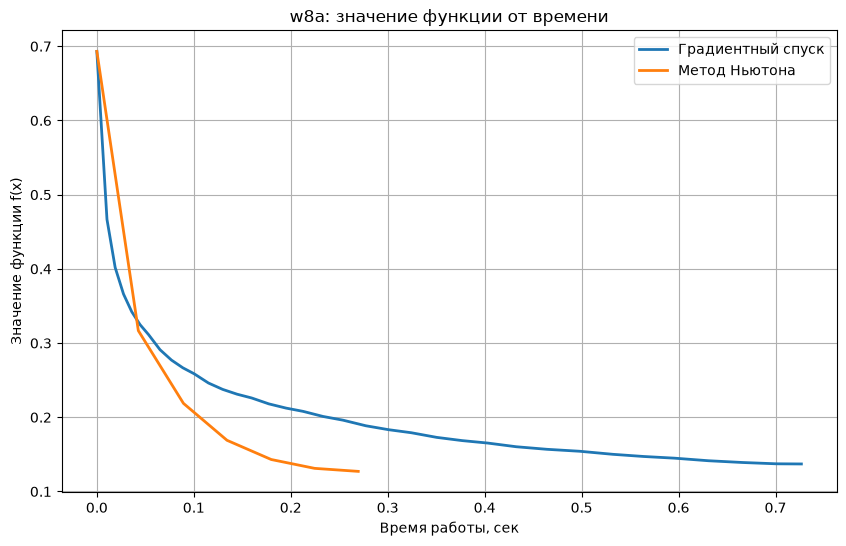

In [10]:
plt.figure(figsize=(10, 6))

plt.plot(hist_gd['time'],hist_gd['func'],label='Градиентный спуск',linewidth=2)

plt.plot(hist_newton['time'],hist_newton['func'],label='Метод Ньютона',linewidth=2)

plt.xlabel('Время работы, сек')
plt.ylabel('Значение функции f(x)')
plt.title('w8a: значение функции от времени')
plt.legend()
plt.grid(True)
plt.show()

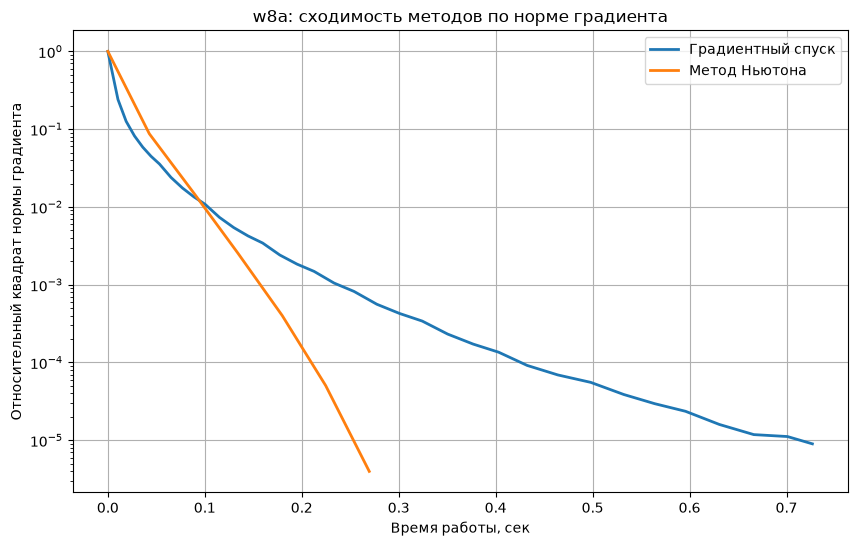

In [11]:
# Нормы градиентов из истории
grad_gd = np.asarray(hist_gd['grad_norm'])
grad_newton = np.asarray(hist_newton['grad_norm'])

# Относительные квадраты норм
rel_gd = (grad_gd / grad_gd[0])**2
rel_newton = (grad_newton / grad_newton[0])**2

plt.figure(figsize=(10, 6))

plt.plot(hist_gd['time'],np.maximum(rel_gd, 1e-16),label='Градиентный спуск',linewidth=2)

plt.plot(hist_newton['time'],np.maximum(rel_newton, 1e-16),label='Метод Ньютона',linewidth=2)

plt.yscale('log')
plt.xlabel('Время работы, сек')
plt.ylabel('Относительный квадрат нормы градиента')
plt.title('w8a: сходимость методов по норме градиента')
plt.legend()
plt.grid(True)
plt.show()

### Анализ результатов на w8a
На наборе данных w8a оба метода успешно достигли заданного критерия остановки.
Градиентному спуску потребовалось 35 итераций и 0,724 секунды, тогда как методу Ньютона - 6 итераций и 0,361 секунды.
На графике зависимости значения функции от времени видно, что градиентный спуск быстро уменьшает функцию потерь на начальном этапе, но затем скорость сходимости снижается. Метод Ньютона за меньшее количество итераций достигает более низкого значения функции.
График относительного квадрата нормы градиента показывает, что метод Ньютона быстрее достигает заданной точности.
Таким образом, на наборе w8a метод Ньютона оказался эффективнее по количеству итераций и общему времени работы. Это объясняется использованием гессиана, позволяющего учитывать кривизну функции при выборе направления спуска.

### gisette

In [16]:
# Загружаем gisette
A_g, b_g = load_dataset('gisette')

m_g, n_g = A_g.shape

# Создаём оракул с регуляризацией lambda = 1/m
oracle_g = LogRegL2Oracle(A_g, b_g, regcoef=1.0 / m_g)

# Начальная точка
x0_g = np.zeros(n_g)

# Запускаем градиентный спуск
x_gd_g, msg_gd_g, hist_gd_g = gradient_descent(oracle_g,x0_g,trace=True)

print("Градиентный спуск на gisette:")
print("Статус:", msg_gd_g)
print("Число итераций:", len(hist_gd_g['func']) - 1)
print("Время:", hist_gd_g['time'][-1], "сек")


Датасет: gisette
Количество объектов m = 6000
Количество признаков n = 5000
Классы: [-1.  1.]
Коэффициент регуляризации: 0.00016667
Память для одного плотного гессиана: 0.186 ГиБ
Градиентный спуск на gisette:
Статус: success
Число итераций: 1221
Время: 409.531545 сек


In [17]:
# Метод Ньютона на gisette
x_newton_g, msg_newton_g, hist_newton_g = newton(oracle_g,x0_g,trace=True)

print("Метод Ньютона на gisette:")
print("Статус:", msg_newton_g)
print("Число итераций:", len(hist_newton_g['func']) - 1)
print("Время:", hist_newton_g['time'][-1], "сек")

Метод Ньютона на gisette:
Статус: success
Число итераций: 6
Время: 938.142198 сек


In [20]:
def plot_comparison(name, history_gd, history_newton):

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    methods = [('Градиентный спуск', history_gd),('Метод Ньютона', history_newton)]

    for label, history in methods:
        time = np.asarray(history['time'])
        func_values = np.asarray(history['func'])
        grad_norm = np.asarray(history['grad_norm'])

        # Первый график: функция от времени
        axes[0].plot(time,func_values,linewidth=2,label=label)

        # Второй график: относительный квадрат нормы градиента
        relative_grad = (grad_norm / grad_norm[0])**2

        # Для логарифмической шкалы оставляем
        # только положительные значения
        valid = relative_grad > 0
        axes[1].plot(time[valid],relative_grad[valid],linewidth=2,label=label)

    # Оформление первого графика
    axes[0].set_title(f'{name}: значение функции')
    axes[0].set_xlabel('Время работы, сек')
    axes[0].set_ylabel('Значение функции f(x)')
    axes[0].legend()
    axes[0].grid(True)

    # Оформление второго графика
    axes[1].set_title(f'{name}: норма градиента')
    axes[1].set_xlabel('Время работы, сек')
    axes[1].set_ylabel('Относительный квадрат нормы градиента')
    axes[1].set_yscale('log')
    axes[1].legend()
    axes[1].grid(True)
    plt.tight_layout()
    plt.show() 

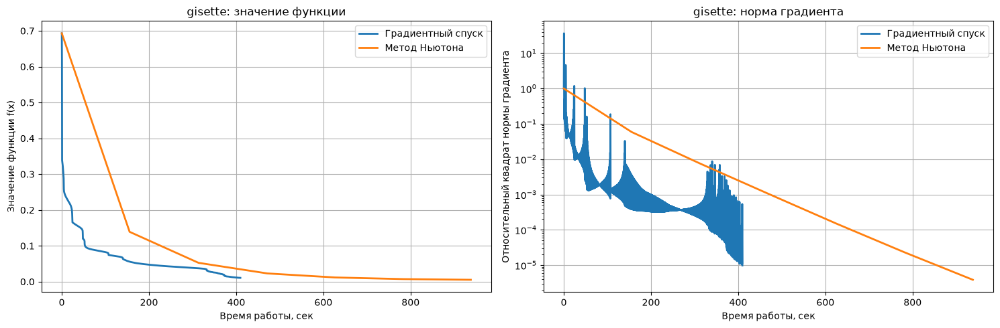

In [21]:
plot_comparison('gisette', hist_gd_g, hist_newton_g)

### Анализ результатов эксперимента на gisette
На наборе данных gisette, содержащем 6000 объектов и 5000 признаков, оба метода успешно достигли заданного критерия остановки.
Градиентный спуск выполнил 1221 итерацию за 409,53 секунды, в то время как метод Ньютона потребовал всего 6 итераций, но затратил 938,14 секунды.
На графике зависимости значения функции от времени видно, что градиентный спуск быстро уменьшает функцию потерь на начальном этапе, после чего скорость сходимости постепенно снижается. Метод Ньютона также обеспечивает уменьшение функции, однако каждая его итерация занимает значительно больше времени.
На графике относительного квадрата нормы градиента наблюдаются колебания для градиентного спуска. Это объясняется тем, что уменьшение значения функции не гарантирует монотонного уменьшения нормы градиента. Метод Ньютона демонстрирует более плавное снижение этой величины.
Таким образом, несмотря на то что метод Ньютона потребовал примерно в 204 раза меньше итераций, градиентный спуск оказался быстрее по реальному времени примерно в 2,3 раза. Это связано с высокой вычислительной стоимостью построения гессиана и выполнения разложения Холецкого при большой размерности пространства.


### Сравнение результатов w8a и gisette
На наборе данных w8a, содержащем 49749 объектов и 300 признаков, метод Ньютона оказался эффективнее градиентного спуска. Он достиг заданной точности за 6 итераций и 0,361 секунды, тогда как градиентному спуску потребовалось 35 итераций и 0,724 секунды.
Однако на gisette наблюдалась противоположная ситуация: метод Ньютона сходился за значительно меньшее число итераций, но требовал больше времени.
Основной причиной различия является размерность пространства. На w8a гессиан имеет размер $(300\times300)$, поэтому его вычисление и разложение относительно недороги. На gisette размер гессиана составляет $(5000\times5000)$, что существенно увеличивает вычислительные затраты метода Ньютона.
Таким образом, увеличение размерности задачи сильнее влияет на стоимость итерации метода Ньютона, чем градиентного спуска.


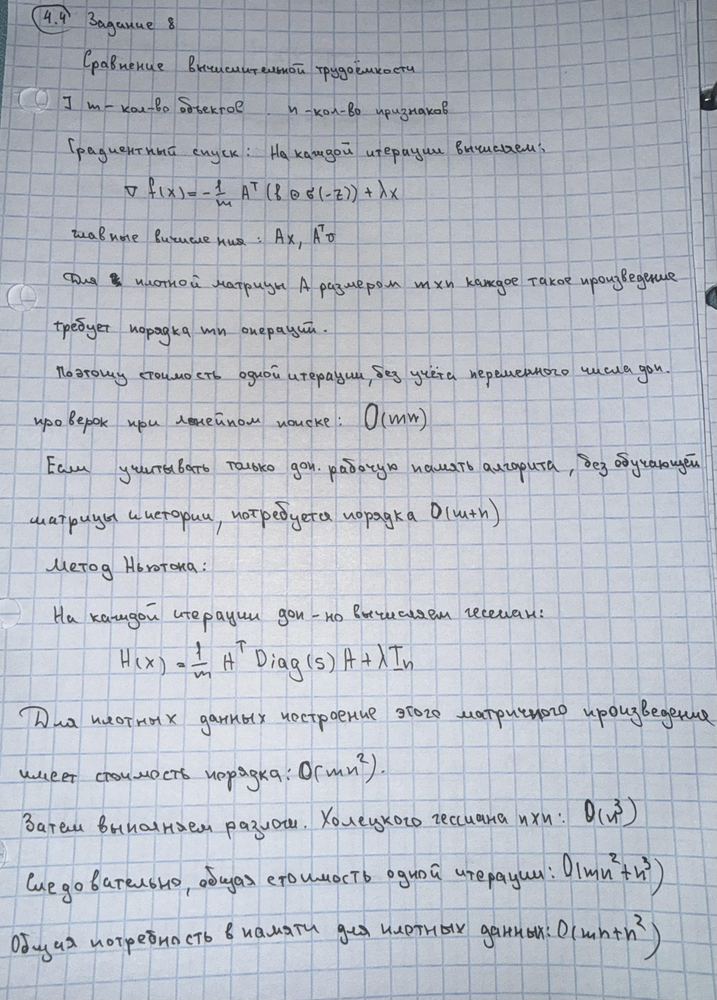

## Общий вывод по заданию 8
В ходе эксперимента было проведено сравнение градиентного спуска и метода Ньютона при обучении логистической регрессии с L2-регуляризацией на двух наборах данных: w8a и gisette.
Результаты показали, что метод Ньютона может быть эффективнее на задачах относительно небольшой размерности благодаря быстрому уменьшению ошибки за малое количество итераций.
Однако при увеличении числа признаков вычисление и разложение гессиана становятся затратными. Поэтому на задачах большой размерности градиентный спуск может превосходить метод Ньютона по времени работы, несмотря на большее количество итераций.
Следовательно, выбор метода оптимизации зависит не только от скорости сходимости по итерациям, но и от вычислительной стоимости каждого шага, размерности пространства и структуры обучающих данных.
Итог: метод Ньютона целесообразен, когда размерность задачи позволяет эффективно вычислять и обрабатывать гессиан. Градиентный спуск более экономичен по памяти и может быть предпочтительнее для задач с большим количеством признаков.


# Оформление и проверка задания

## Что сдавать

Результатом выполнения задания являются:

1. Файлы `optimization.py` и `oracles.py` с реализованными методами и оракулами.
2. Полные исходные коды для проведения экспериментов и рисования всех графиков. Все результаты должны быть воспроизводимыми; если вы используете случайность — зафиксируйте `seed`.
3. Отчёт в формате `.ipynb` о проведённых исследованиях.

## Требования к отчёту

Каждый эксперимент (задания 3, 4 и 8) оформите в виде отдельного раздела отчёта. Для каждого эксперимента необходимо сначала написать его описание: какие функции оптимизируются, каким образом генерируются данные, какие методы и с какими параметрами используются. Далее должны быть представлены результаты соответствующего эксперимента — графики, таблицы и т. д. Наконец, после результатов должны быть написаны ваши выводы: какая зависимость наблюдается и почему.

**Важно:** отчёт не должен содержать много кода. Каждый график должен быть прокомментирован: что на нём изображено и какие выводы можно сделать из этого эксперимента. У графиков обязательно должны быть подписаны оси; если на графике нарисовано несколько кривых, должна быть легенда. Сами линии следует рисовать достаточно толстыми, чтобы они были хорошо видимыми.

## Проверка и оценивание

Перед отправкой задания обязательно убедитесь, что ваша реализация проходит автоматические предварительные тесты `presubmit_tests.py`, выданные вместе с заданием. Для этого запустите следующую команду:

```
python -m pytest presubmit_tests.py
```

**Важно:** решения, которые не будут проходить тесты `presubmit_tests.py`, будут автоматически оценены в **0 баллов**. Проверяющий не будет разбираться, почему ваш код не работает, и читать ваш отчёт.

Оценка за задание будет складываться из двух частей:

1. Правильность и эффективность реализованного кода — оценивается автоматически с помощью независимых тестов (отличных от предварительных).
2. Качество отчёта — оценивается проверяющим. При этом оценка может быть субъективной и апелляции не подлежит.

За реализацию модификаций алгоритмов и хорошие дополнительные эксперименты могут быть начислены дополнительные баллы. Начисление этих баллов является субъективным и безапелляционным.

**Важно:** практическое задание выполняется самостоятельно. Если вы получили ценные советы (по реализации или проведению экспериментов) от другого студента, об этом должно быть явно написано в отчёте. В противном случае «похожие» решения считаются плагиатом, и все задействованные студенты (в том числе те, у кого списали) будут сурово наказаны.